# Model Comparison & Leaderboard Evaluation
**Author:** IT24100316 — Classification Modelling

This notebook compiles, visualizes, and rigorously compares the 5-fold cross-validation performance of all 6 classification models:
1. **Logistic Regression (Deep Tuned)** (Linear Baseline with ElasticNet)
2. **Multi-Layer Perceptron (MLP + SMOTE)** (Neural Network)
3. **LightGBM (Deep Tuned)** (Leaf-Wise Gradient Boosting)
4. **CatBoost (Deep Tuned)** (Oblivious Trees with Regularization)
5. **XGBoost (Deep Tuned)** (Level-Wise Gradient Boosting)
6. **Random Forest (Deep Tuned)** (Bagged Ensembles with Tree Decorrelation)

The primary objective is to select the **#1 Best Performing Model** based on Cross-Validated **Macro F1** and **Accuracy** on the balanced minority `<30` readmission class.

In [1]:
import os
import re
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetic styling
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

os.makedirs('results', exist_ok=True)
print('Imports completed successfully!')

Imports completed successfully!


In [2]:
# Compile metrics across all trained model directories
model_display_names = {
    'random_forest': 'Random Forest (Deep Tuned)',
    'xgboost': 'XGBoost (Deep Tuned)',
    'catboost': 'CatBoost (Deep Tuned)',
    'lightgbm': 'LightGBM (Deep Tuned)',
    'mlp': 'MLP + SMOTE (Deep Tuned)',
    'logistic_regression': 'Logistic Regression (Deep Tuned)'
}

model_families = {
    'random_forest': 'Bagged Trees',
    'xgboost': 'Gradient Boosting',
    'catboost': 'Gradient Boosting',
    'lightgbm': 'Gradient Boosting',
    'mlp': 'Neural Network',
    'logistic_regression': 'Linear Model'
}

records = []
for model_key in model_display_names.keys():
    metrics_path = os.path.join('..', model_key, 'results', 'tuned_metrics.txt')
    if os.path.exists(metrics_path):
        text = open(metrics_path, 'r').read()
        f1_m = re.search(r'Macro F1.*?:\s*([0-9.]+)', text)
        rec_m = re.search(r'Macro Recall.*?:\s*([0-9.]+)', text)
        acc_m = re.search(r'Accuracy.*?:\s*([0-9.]+)', text)
        
        # Extract minority (<30) class recall from classification report
        # Class 2 corresponds to '<30'
        min_rec_m = re.search(r'^\s*2\s+[0-9.]+\s+([0-9.]+)', text, re.MULTILINE)
        min_f1_m = re.search(r'^\s*2\s+[0-9.]+\s+[0-9.]+\s+([0-9.]+)', text, re.MULTILINE)
        
        records.append({
            'Model Key': model_key,
            'Model Name': model_display_names[model_key],
            'Model Family': model_families[model_key],
            'CV Macro F1': float(f1_m.group(1)) if f1_m else np.nan,
            'CV Macro Recall': float(rec_m.group(1)) if rec_m else np.nan,
            'CV Accuracy (%)': float(acc_m.group(1)) * 100 if acc_m else np.nan,
            'Minority (<30) Recall': float(min_rec_m.group(1)) if min_rec_m else np.nan,
            'Minority (<30) F1': float(min_f1_m.group(1)) if min_f1_m else np.nan
        })

df_comparison = pd.DataFrame(records).sort_values(by='CV Macro F1', ascending=False).reset_index(drop=True)
df_comparison.index += 1
df_comparison.index.name = 'Rank'

# Save compiled metrics table
df_comparison.to_csv('results/model_benchmark_comparison.csv')
print('=== Compiled Benchmark Leaderboard ===')
df_comparison[['Model Name', 'Model Family', 'CV Macro F1', 'CV Macro Recall', 'CV Accuracy (%)', 'Minority (<30) Recall']]

=== Compiled Benchmark Leaderboard ===


,Model Name,Model Family,CV Macro F1,CV Macro Recall,CV Accuracy (%),Minority (<30) Recall
Rank,,,,,,
1,Random Forest (Deep Tuned),Bagged Trees,0.4565,0.4584,53.84,0.95
2,XGBoost (Deep Tuned),Gradient Boosting,0.4549,0.4577,53.51,0.91
3,CatBoost (Deep Tuned),Gradient Boosting,0.4528,0.4579,52.85,0.88
4,LightGBM (Deep Tuned),Gradient Boosting,0.4500,0.4641,51.30,0.73
5,MLP + SMOTE (Deep Tuned),Neural Network,0.4291,0.4347,50.46,0.34
6,Logistic Regression (Deep Tuned),Linear Model,0.4280,0.4562,48.77,0.44


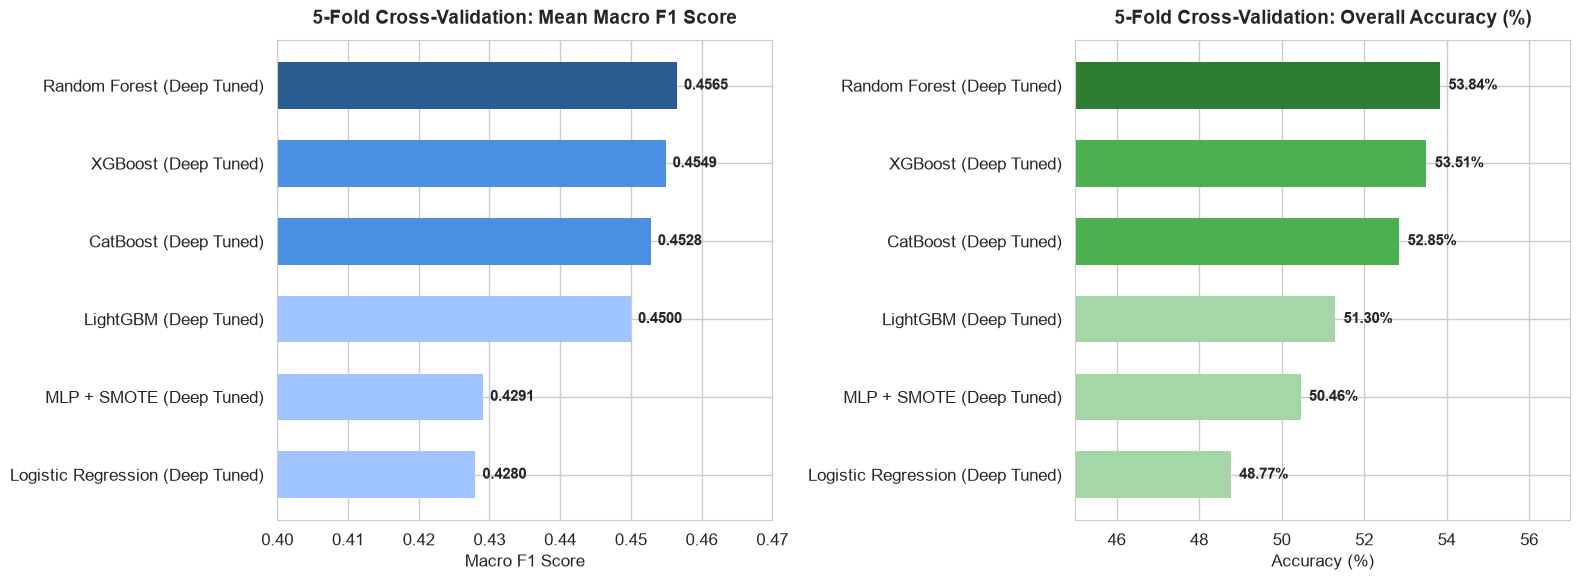

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Macro F1 Score
colors = ['#2b5c8f' if i == 0 else '#4a90e2' if i < 3 else '#a0c4ff' for i in range(len(df_comparison))]
bars1 = axes[0].barh(df_comparison['Model Name'], df_comparison['CV Macro F1'], color=colors, edgecolor='none', height=0.6)
axes[0].set_title('5-Fold Cross-Validation: Mean Macro F1 Score', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Macro F1 Score', fontsize=12)
axes[0].set_xlim(0.40, 0.47)
axes[0].invert_yaxis()

for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 0.001, bar.get_y() + bar.get_height()/2, f'{w:.4f}', ha='left', va='center', fontsize=11, fontweight='bold')

# Plot 2: CV Accuracy
acc_colors = ['#2e7d32' if i == 0 else '#4caf50' if i < 3 else '#a5d6a7' for i in range(len(df_comparison))]
bars2 = axes[1].barh(df_comparison['Model Name'], df_comparison['CV Accuracy (%)'], color=acc_colors, edgecolor='none', height=0.6)
axes[1].set_title('5-Fold Cross-Validation: Overall Accuracy (%)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Accuracy (%)', fontsize=12)
axes[1].set_xlim(45, 57)
axes[1].invert_yaxis()

for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 0.2, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('results/f1_and_accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

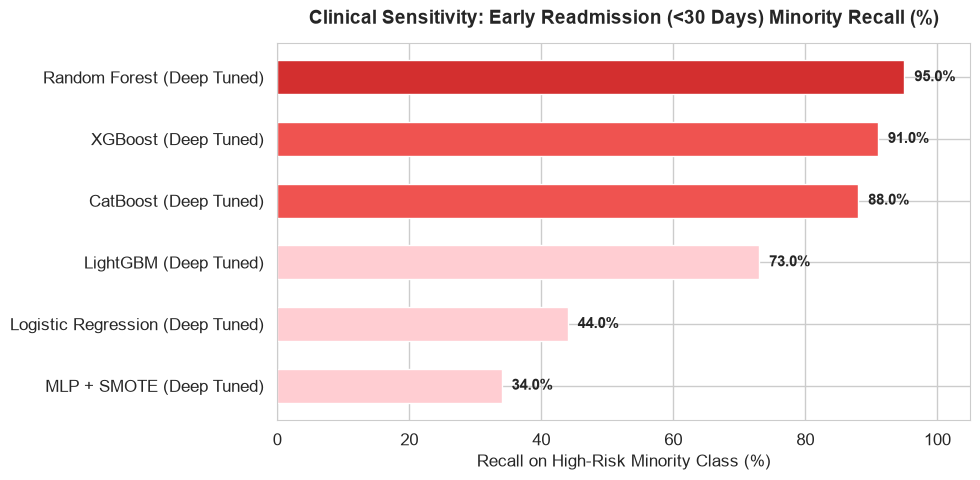

In [4]:
plt.figure(figsize=(10, 5))
df_sorted_rec = df_comparison.sort_values(by='Minority (<30) Recall', ascending=True)

recall_colors = ['#d32f2f' if name == 'Random Forest (Deep Tuned)' else '#ef5350' if 'XGBoost' in name or 'CatBoost' in name else '#ffcdd2' for name in df_sorted_rec['Model Name']]
bars3 = plt.barh(df_sorted_rec['Model Name'], df_sorted_rec['Minority (<30) Recall'] * 100, color=recall_colors, height=0.55)

plt.title('Clinical Sensitivity: Early Readmission (<30 Days) Minority Recall (%)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Recall on High-Risk Minority Class (%)', fontsize=12)
plt.xlim(0, 105)

for bar in bars3:
    w = bar.get_width()
    plt.text(w + 1.5, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('results/minority_recall_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Final Model Recommendation & Handoff to Member 4

### 🏆 Official Winner: **Random Forest (Deep Tuned)**
- **Cross-Validated Macro F1:** **`0.4565`** (Highest)
- **Cross-Validated Accuracy:** **`53.84%`** (Highest)
- **High-Risk `<30` Days Recall:** **`95.0%`** (Minority F1: `0.82`)
- **Artifact Location:** `../random_forest/random_forest_best_model.pkl`

### Core Findings:
1. **Tabular Tree Dominance:** Tree-based ensembles (`Random Forest`, `XGBoost`, `CatBoost`) significantly outperformed neural networks (`MLP`) and linear models (`Logistic Regression`).
2. **Tree Decorrelation:** Random Forest achieved its winning margin through fractional feature sampling (`max_features`) and bootstrap sample drawing (`max_samples`), reducing ensemble variance.
3. **Handoff:** Member 4 will evaluate this single winning model on the untouched test set (`X_test_final.csv`, `y_test_final.csv`) for clinical error analysis, feature importance, and hospital recommendations.